## EN3160 Image Processing and Machine Vision
#### Assignment 03
#### Ratnayake R.M.S.H., 230548R

Epoch 1/20, Loss: 0.9768668603897095
Epoch 2/20, Loss: 0.9497923175096512
Epoch 3/20, Loss: 0.9360698091387749
Epoch 4/20, Loss: 0.9275258416533471
Epoch 5/20, Loss: 0.9215908589363098
Epoch 6/20, Loss: 0.9171896069049835
Epoch 7/20, Loss: 0.9137792538404464
Epoch 8/20, Loss: 0.9110522292852402
Epoch 9/20, Loss: 0.9088229956030845
Epoch 10/20, Loss: 0.906970354616642
Epoch 11/20, Loss: 0.905410423219204
Epoch 12/20, Loss: 0.9040831523537636
Epoch 13/20, Loss: 0.9029446550607682
Epoch 14/20, Loss: 0.9019612877964973
Epoch 15/20, Loss: 0.9011075037121773
Epoch 16/20, Loss: 0.9003625238537788
Epoch 17/20, Loss: 0.8997100005149842
Epoch 18/20, Loss: 0.8991364462375641
Epoch 19/20, Loss: 0.8986309376955033
Epoch 20/20, Loss: 0.8981844918727875


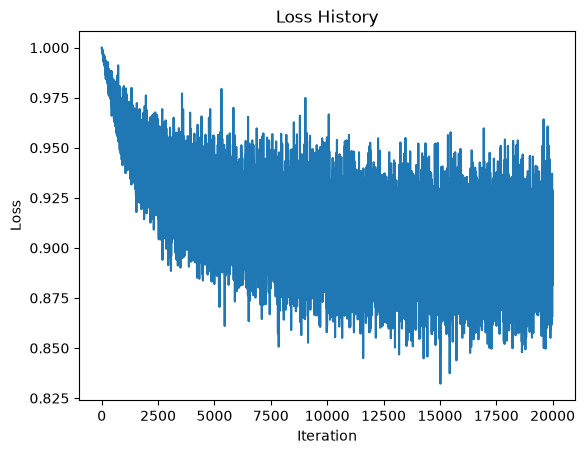

Training accuracy: 32.21%
Test accuracy: 32.41%


In [6]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ("plane", "car", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")

# 2. Network parameters
Din = 3 * 32 * 32   # flattened CIFAR-10 image size
K = 10              # number of classes
std = 1e-5

# One layer: directly map input to output
w = torch.randn(Din, K) * std
b = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 2e-6           # learning rate
lr_decay = 0.9      # learning rate decay
reg = 0             # regularization strength

loss_history = []

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)                                # (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()     # (Ntr, K)

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss: mean squared error with L2 regularization
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) \
               + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5 & 6. Accuracy evaluation
def evaluate(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            predicted = torch.argmax(x.mm(w) + b, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


train_acc = evaluate(trainloader)
print(f"Training accuracy: {train_acc:.2f}%")

test_acc = evaluate(testloader)
print(f"Test accuracy: {test_acc:.2f}%")

### Question 2

2.11.0+cu128
Using device: cuda
Epoch 1/10 | Loss: 0.2453 | Train Acc: 97.11% | Test Acc: 97.24%
Epoch 2/10 | Loss: 0.0747 | Train Acc: 98.16% | Test Acc: 98.37%
Epoch 3/10 | Loss: 0.0533 | Train Acc: 98.67% | Test Acc: 98.45%
Epoch 4/10 | Loss: 0.0420 | Train Acc: 98.83% | Test Acc: 98.57%
Epoch 5/10 | Loss: 0.0344 | Train Acc: 99.27% | Test Acc: 98.86%
Epoch 6/10 | Loss: 0.0286 | Train Acc: 99.44% | Test Acc: 98.97%
Epoch 7/10 | Loss: 0.0245 | Train Acc: 99.51% | Test Acc: 98.95%
Epoch 8/10 | Loss: 0.0209 | Train Acc: 99.44% | Test Acc: 99.04%
Epoch 9/10 | Loss: 0.0174 | Train Acc: 99.59% | Test Acc: 99.00%
Epoch 10/10 | Loss: 0.0156 | Train Acc: 99.66% | Test Acc: 98.89%


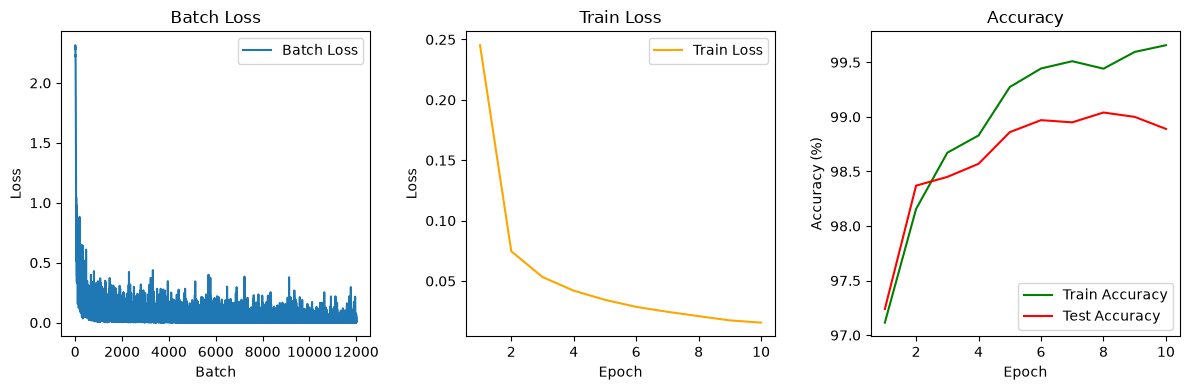

In [2]:
import torch
print(torch.__version__)
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5,stride=1, padding=0)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=0)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        #flatten layer
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool2(x)

        x = x.view(-1, 16 * 5 * 5)  # Flatten the tensor
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

# Print the NN architecture

batch_size = 50
data_root = './data'

trainset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = LeNet5().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

batch_losses = []
train_losses = []
train_accuracies = []
test_accuracies = []

def accuracy(loader):
    model.eval() # Ensure model is in eval mode during evaluation
    correct, total = 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

epochs = 10
for epoch in range(epochs):
    # Implement the training loop for one epoch
    model.train()  # Set the model to training mode
    running_loss = 0.0
    for i, (data, labels) in enumerate(trainloader):
        data, labels = data.to(device), labels.to(device)
        
        optimizer.zero_grad()  # Zero the gradients
        outputs = model(data)  # Forward pass
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()  # Backward pass
        optimizer.step()  # Update weights
        
        running_loss += loss.item()
        batch_losses.append(loss.item())

    

    avg_loss = running_loss / len(trainloader)
    train_losses.append(avg_loss)
    
    # --- FIXED: Calculate accuracy per epoch inside the loop ---
    train_acc = accuracy(trainloader)
    test_acc = accuracy(testloader)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    
    print(f"Epoch {epoch + 1}/{epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

# Plotting code remains the same, but now it will display 5 points connected by lines!
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(batch_losses, label='Batch Loss')
plt.title('Batch Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss', color='orange')
plt.title('Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(1, epochs + 1), train_accuracies, label='Train Accuracy', color='green')
plt.plot(range(1, epochs + 1), test_accuracies, label='Test Accuracy', color='red')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

### Implementing modern CNN

2.11.0+cu128
Using device: cuda
113386 parameters
Epoch 1/10 | Loss: 0.1470 | Train Acc: 98.04% | Test Acc: 98.13%
Epoch 2/10 | Loss: 0.0672 | Train Acc: 99.19% | Test Acc: 98.98%
Epoch 3/10 | Loss: 0.0493 | Train Acc: 99.27% | Test Acc: 99.09%
Epoch 4/10 | Loss: 0.0443 | Train Acc: 98.90% | Test Acc: 98.68%
Epoch 5/10 | Loss: 0.0381 | Train Acc: 99.45% | Test Acc: 99.21%
Epoch 6/10 | Loss: 0.0335 | Train Acc: 99.52% | Test Acc: 99.27%
Epoch 7/10 | Loss: 0.0266 | Train Acc: 99.65% | Test Acc: 99.24%
Epoch 8/10 | Loss: 0.0242 | Train Acc: 99.68% | Test Acc: 99.35%
Epoch 9/10 | Loss: 0.0222 | Train Acc: 99.78% | Test Acc: 99.47%
Epoch 10/10 | Loss: 0.0211 | Train Acc: 99.47% | Test Acc: 98.90%


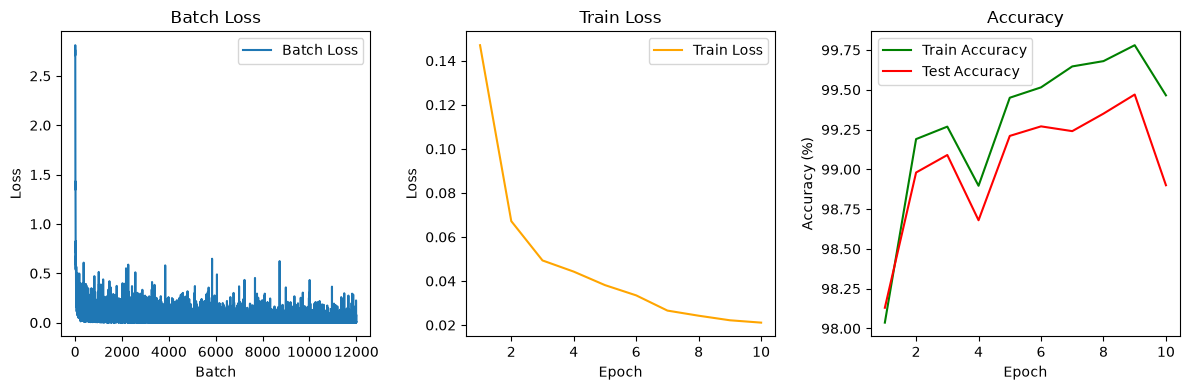

In [4]:
import torch
print(torch.__version__)
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

class NewCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1= nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1,bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block2= nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1,padding=1,bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block3= nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1,padding=1,bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 *4*4, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.dropout(x)
        x = self.fc1(x)
        return x

    
transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

#  # instead of LeNet5()


batch_size = 50
data_root = './data'

trainset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model2 = NewCNN().to(device)
print(sum(p.numel() for p in model2.parameters()), "parameters")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model2.parameters(), lr=0.001)

batch_losses2 = []
train_losses2 = []
train_accuracies2 = []
test_accuracies2 = []

def accuracy(loader):
    model2.eval() # Ensure model is in eval mode during evaluation
    correct, total = 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model2(data)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

epochs = 10
for epoch in range(epochs):
    # Implement the training loop for one epoch
    model2.train()  # Set the model to training mode
    running_loss1 = 0.0
    for i, (data, labels) in enumerate(trainloader):
        data, labels = data.to(device), labels.to(device)
        
        optimizer.zero_grad()  # Zero the gradients
        outputs2 = model2(data)  # Forward pass
        loss = criterion(outputs2, labels)  # Compute loss
        loss.backward()  # Backward pass
        optimizer.step()  # Update weights
        
        running_loss1 += loss.item()
        batch_losses2.append(loss.item())

    

    avg_loss = running_loss1 / len(trainloader)
    train_losses2.append(avg_loss)
    
    # --- FIXED: Calculate accuracy per epoch inside the loop ---
    train_acc = accuracy(trainloader)
    test_acc = accuracy(testloader)
    train_accuracies2.append(train_acc)
    test_accuracies2.append(test_acc)
    
    print(f"Epoch {epoch + 1}/{epochs} | Loss: {avg_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

# Plotting code remains the same, but now it will display 5 points connected by lines!
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(batch_losses2, label='Batch Loss')
plt.title('Batch Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(1, epochs + 1), train_losses2, label='Train Loss', color='orange')
plt.title('Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(1, epochs + 1), train_accuracies2, label='Train Accuracy', color='green')
plt.plot(range(1, epochs + 1), test_accuracies2, label='Test Accuracy', color='red')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

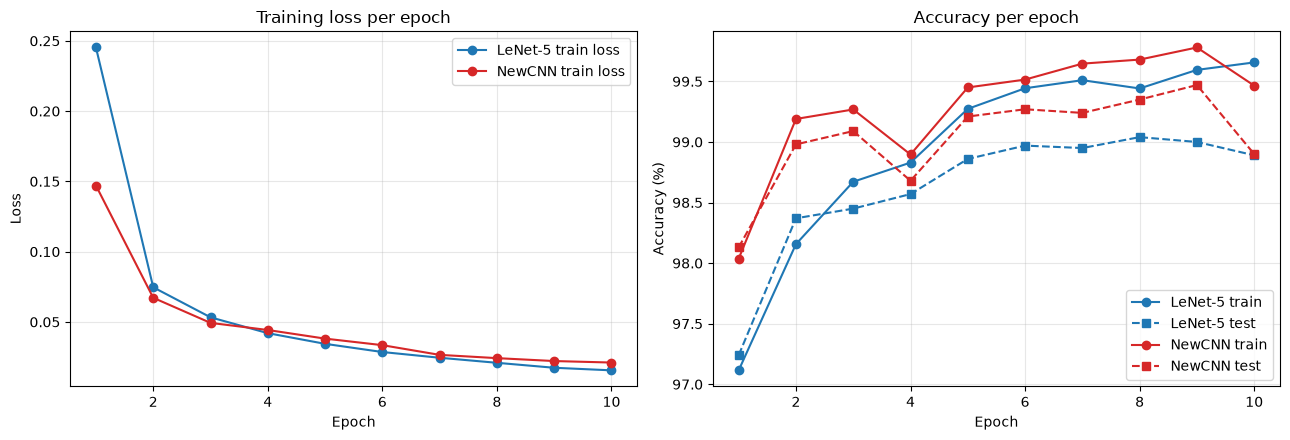

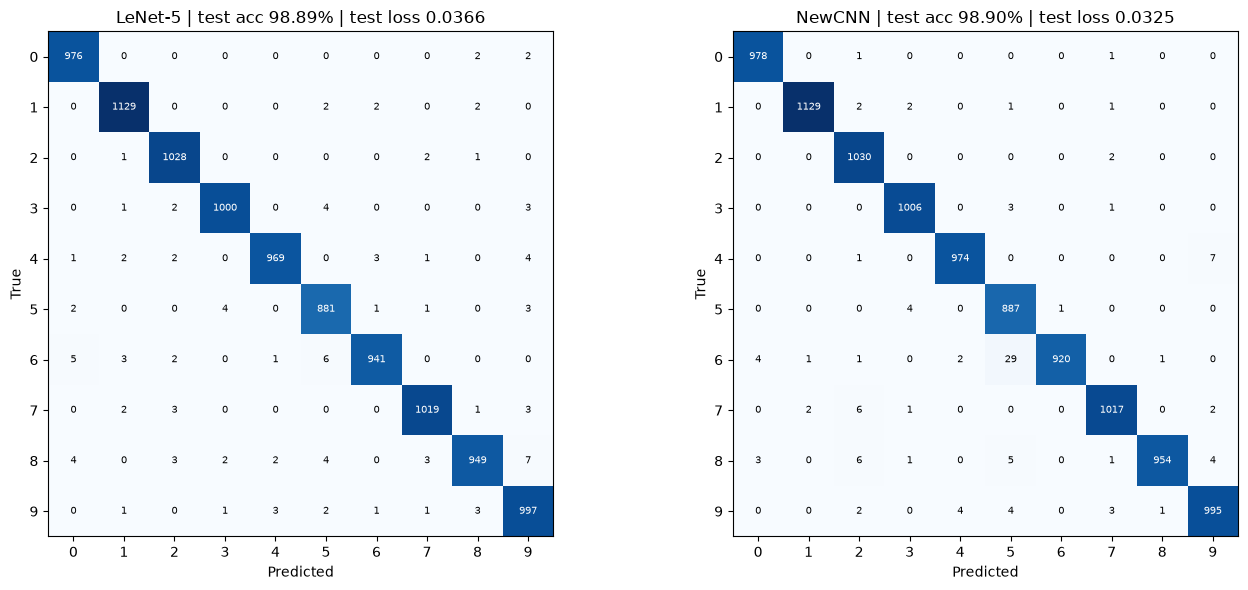

In [5]:
import numpy as np

@torch.no_grad()
def predict(net, loader):
    net.eval()
    preds, labels_all, loss_sum = [], [], 0.0
    for data, labels in loader:
        data, labels = data.to(device), labels.to(device)
        out = net(data)
        loss_sum += criterion(out, labels).item() * labels.size(0)
        preds.append(out.argmax(1).cpu())
        labels_all.append(labels.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels_all).numpy(), loss_sum / len(loader.dataset)

def conf_matrix(preds, labels, n=10):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (labels, preds), 1)
    return cm

ep = range(1, epochs + 1)

# ---- per-epoch curves, both models
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, train_losses,  "-o", color="tab:blue", label="LeNet-5 train loss")
ax[0].plot(ep, train_losses2, "-o", color="tab:red",  label="NewCNN train loss")
ax[0].set(title="Training loss per epoch", xlabel="Epoch", ylabel="Loss")

ax[1].plot(ep, train_accuracies,  "-o",  color="tab:blue", label="LeNet-5 train")
ax[1].plot(ep, test_accuracies,   "--s", color="tab:blue", label="LeNet-5 test")
ax[1].plot(ep, train_accuracies2, "-o",  color="tab:red",  label="NewCNN train")
ax[1].plot(ep, test_accuracies2,  "--s", color="tab:red",  label="NewCNN test")
ax[1].set(title="Accuracy per epoch", xlabel="Epoch", ylabel="Accuracy (%)")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# ---- confusion matrices on the test set
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, net) in zip(ax, [("LeNet-5", model), ("NewCNN", model2)]):
    p, l, test_loss = predict(net, testloader)
    cm = conf_matrix(p, l)
    a.imshow(cm, cmap="Blues")
    a.set(title=f"{name} | test acc {100*(p==l).mean():.2f}% | test loss {test_loss:.4f}",
          xlabel="Predicted", ylabel="True", xticks=range(10), yticks=range(10))
    for i in range(10):
        for j in range(10):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()